# Sampling a real circuit

This tutorial replaces the exact-weight sampler with a real quantum circuit and runs both on three molecules. It takes about 25 minutes and picks up where Tutorial 3 left off.

The first cell runs `make compare-molecules`, which builds the molecules, the circuits and the comparison that the later sections read. If you open this outside the repo, or on Colab, it downloads the code from GitHub first.

In [1]:
import importlib.util
import os
import sys

import matplotlib.pyplot as plt
import numpy as np

ROOT = ""  # if your COBWEB folder is somewhere else, set this to its path
if not len(ROOT):
    ROOT = "../.." if os.path.isdir("../../src") else "COBWEB"
if not os.path.isdir(f"{ROOT}/src"):
    !git clone -q https://github.com/DChristensen12/COBWEB.git {ROOT}
for package in ["pyscf", "ffsim"]:
    if importlib.util.find_spec(package) is None:
        %pip install -q {package}
!make -C {ROOT} compare-molecules

import ffsim
from pyscf import cc, gto, scf

sys.path.append(f"{ROOT}/src")
from circuits import configs_from_bitstrings, lucj_state
from molecules import MOLECULES as GEOMETRIES
from molecules import determinant_labels

plt.style.use(f"{ROOT}/figures.mplstyle")
os.makedirs(f"{ROOT}/figures/week4", exist_ok=True)

MOLECULES = ["h4", "lih", "h2o"]
NAMES = {"h4": "stretched H4", "lih": "LiH", "h2o": "water"}
MHA = 1000  # hartree to millihartree


def check(guess, answer, tol=0):
    if guess is None:
        print("Put your guess in first, then run this cell again")
        return
    right = guess == answer if isinstance(answer, str) else abs(guess - answer) <= tol
    print(f"Correct, it's {answer}" if right else f"Not quite. You said {guess}, it's {answer}")

make: Entering directory '/tmp/y/done'
for m in h4 lih h2o; do python src/molecules.py -m $m; done


h4: 8 orbitals, (2, 2) electrons, H has a shape of (784, 784)


Hartree-Fock -1.997566, full CI -2.108280 hartree
Correlation energy -0.110715 hartree


lih: 6 orbitals, (2, 2) electrons, H has a shape of (225, 225)


Hartree-Fock -7.861865, full CI -7.882324 hartree
Correlation energy -0.020460 hartree


...

Growing with Epstein-Nesbet


Sampling the exact state, 20 repeats of 20000 shots


Found 29 of 441 configurations
Sampling the LUCJ circuit, 20 repeats of 20000 shots


Found 12 of 441 configurations


make: Leaving directory '/tmp/y/done'


## Where we left off

Until now our sampler drew straight from the exact answer. That is what a perfect circuit would give, so we have been calling it the best case. A quantum computer instead prepares an approximate state and measures it. This tutorial builds that approximate state and measures it on a simulator.

## The circuit

The circuit is called LUCJ, short for local unitary cluster Jastrow. It starts from the Hartree-Fock determinant and applies two kinds of operations. Orbital rotations mix the orbitals together, and Jastrow terms add a phase that depends on which pairs of orbitals are filled.

We don't fit any parameters. They come straight from CCSD, a standard classical method, through `ffsim`. "Local" means we only keep pairs of orbitals that sit on neighbouring qubits. We use the pattern for a square grid of qubits. ibm_kingston, the Heron chip on IBM's free plan, uses a heavy-hex layout instead, so we will switch patterns before running on hardware.

Each orbital needs one qubit for each spin. LiH has 6 orbitals here. How many qubits does its circuit use?

In [2]:
my_guess = None

Now we'll build the circuit for LiH and check.

In [3]:
vec, e_lucj, norb, nelec = lucj_state("lih")
check(my_guess, 2 * norb)
print(f"State vector has a shape of {vec.shape}, one entry per configuration")

Put your guess in first, then run this cell again
State vector has a shape of (225,), one entry per configuration


## How good is the circuit's energy?

We'll compare three energies for each molecule. Hartree-Fock is the starting guess and full CI is the exact answer. The gap between them is the correlation energy, and a good circuit should recover most of it.

Before you look: for stretched H4, is the circuit's energy closer to Hartree-Fock or to full CI? Answer "hartree-fock" or "full ci".

In [4]:
my_guess = None

In [5]:
recovered = {}
for m in MOLECULES:
    H = np.load(f"{ROOT}/results/hamiltonians/{m}.npz")
    e_hf, e_fci = H["H"][0, 0], H["E"][0]  # row 0 is Hartree-Fock
    e_lucj = float(np.load(f"{ROOT}/results/circuits/{m}.npz")["e_lucj"])
    recovered[m] = (e_lucj - e_hf) / (e_fci - e_hf)
    print(f"{NAMES[m]:>12}: recovers {recovered[m]:.0%} of the correlation energy")

check(my_guess, "hartree-fock" if recovered["h4"] < 0.5 else "full ci")

stretched H4: recovers 7% of the correlation energy
         LiH: recovers 69% of the correlation energy
       water: recovers 35% of the correlation energy
Put your guess in first, then run this cell again


The circuit gets most of the way on LiH and almost nowhere on stretched H4. To see why, we'll compare against CCSD itself and against the full version of the circuit, with every pair and every layer kept.

In [6]:
for m in MOLECULES:
    H = np.load(f"{ROOT}/results/hamiltonians/{m}.npz")
    e_hf, e_fci, c0 = H["H"][0, 0], H["E"][0], H["c0"]
    e_ccsd = cc.CCSD(scf.RHF(gto.M(**GEOMETRIES[m], verbose=0)).run()).run().e_tot
    ours, _, _, _ = lucj_state(m)
    full, e_full, _, _ = lucj_state(m, n_reps=None, local=False)

    ccsd_frac = (e_ccsd - e_hf) / (e_fci - e_hf)
    full_frac = (e_full - e_hf) / (e_fci - e_hf)
    print(f"{NAMES[m]:>12}: CCSD {ccsd_frac:.1%}, full circuit {full_frac:.1%}")
    print(f"{'':>12}  Hartree-Fock weight: true state {c0[0] ** 2:.3f}, "
          f"our circuit {abs(ours[0]) ** 2:.3f}, full circuit {abs(full[0]) ** 2:.3f}")

stretched H4: CCSD 99.9%, full circuit 96.3%
              Hartree-Fock weight: true state 0.804, our circuit 0.960, full circuit 0.798


         LiH: CCSD 99.9%, full circuit 99.9%
              Hartree-Fock weight: true state 0.974, our circuit 0.991, full circuit 0.974


       water: CCSD 99.8%, full circuit 99.4%
              Hartree-Fock weight: true state 0.974, our circuit 0.995, full circuit 0.974


Notice that CCSD is not the problem. It recovers over 99% on all three molecules, and the full circuit recovers 96 to 99.9%. Our circuit keeps only 2 layers and only the local pairs, and that is where the energy goes. The pairs we dropped would need qubits that are not wired together on the chip.

The Hartree-Fock weights tell the same story. The full circuit matches the true state closely, while our local circuit piles extra weight onto Hartree-Fock.

## Measuring the circuit

A measurement returns one configuration, as a pair of bit masks for the two spins, and `ffsim` simulates this for us. `configs_from_bitstrings` turns each pair into a row of our matrix. Real hardware returns one bitstring per shot instead, with the beta half on the left and the alpha half on the right. Splitting it gives the same pairs, so this function carries over.

Out of 20,000 measurements of LiH, how many come back as Hartree-Fock? Within 500.

In [7]:
my_guess = None

In [8]:
alpha, beta = ffsim.sample_state_vector(
    vec,
    norb=norb,
    nelec=nelec,
    shots=20000,
    concatenate=False,
    bitstring_type=ffsim.BitstringType.INT,
    seed=0,
)
labels = determinant_labels(norb, nelec)
found, counts = configs_from_bitstrings(alpha, beta, labels)

check(my_guess, int(counts[0]), tol=500)
print(f"{len(found)} different configurations came back")
for row, n in zip(found[:4], counts[:4]):
    print(f"up {labels[row][0]:06b}   down {labels[row][1]:06b}   {n} times")

Put your guess in first, then run this cell again
7 different configurations came back
up 000011   down 000011   19808 times
up 100001   down 100001   74 times
up 000011   down 000101   35 times
up 000101   down 000011   32 times


Notice that almost every shot is Hartree-Fock. The circuit puts nearly all its weight there, so most measurements tell us nothing new.

## How many configurations the circuit finds

`make compare-molecules` sampled each molecule 20 times, once from the exact state and once from the circuit, and tracked how many different configurations turned up as the shots added up.

For stretched H4 at 20,000 shots, the best-case sampler finds about 90 of its 784 configurations. How many does the circuit find? Within 8.

In [9]:
my_guess = None

Put your guess in first, then run this cell again


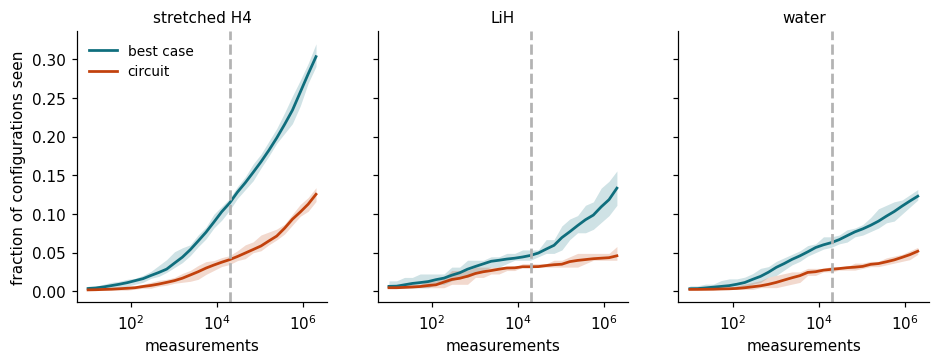

In [10]:
res = {m: np.load(f"{ROOT}/results/compare/{m}.npz") for m in MOLECULES}
check(my_guess, int(np.median(res["h4"]["n_found_circuit"])), tol=8)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True)
for ax, m in zip(axes, MOLECULES):
    d = res[m]
    for key, c, name in [("discovered", "#0f6e7d", "best case"), ("discovered_circuit", "#c2410c", "circuit")]:
        seen = d[key] / d["n_configs"]  # repeats x shots
        ax.semilogx(d["shots"], seen.mean(0), c=c, label=name)
        ax.fill_between(d["shots"], seen.min(0), seen.max(0), color=c, alpha=0.2, lw=0)
    ax.axvline(int(d["n_shots"]), c=(.7, .7, .7), ls="--")  # the 20,000 shot budget
    ax.set_title(NAMES[m])
    ax.set_xlabel("measurements")
axes[0].set_ylabel("fraction of configurations seen")
axes[0].legend()
fig.savefig(f"{ROOT}/figures/week4/discovery.svg")
plt.show()

Notice that the orange circuit curve sits below the best case on every molecule. That is the extra Hartree-Fock weight from earlier. Most shots land on the same configuration, so new ones turn up slowly.

## Head to head

Now the fair comparison. Each method keeps exactly k configurations, for many values of k, and we plot the energy error. Errors are in millihartree (mHa), and the dashed line is 1.6 mHa, the usual target for chemical accuracy.

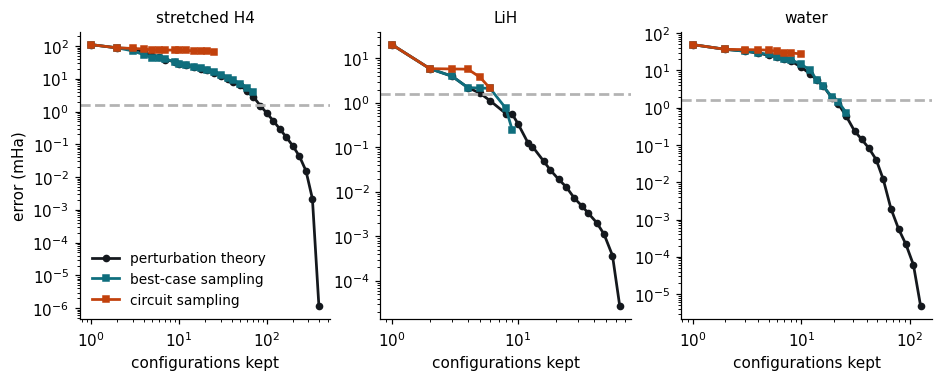

stretched H4: circuit stalls at k = 25, error 67.5 mHa, beats perturbation theory at 0 of 14 sizes
         LiH: circuit stalls at k = 6, error 2.1 mHa, beats perturbation theory at 0 of 6 sizes
       water: circuit stalls at k = 10, error 27.8 mHa, beats perturbation theory at 0 of 9 sizes

stretched H4 at k = 10: perturbation theory 29 mHa, best case 29 mHa, circuit 74 mHa


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, m in zip(axes, MOLECULES):
    d = res[m]
    sizes = d["sizes"]
    keep = d["err_en"] > 1e-10  # once the error hits zero there is nothing to plot
    ax.loglog(sizes[keep], d["err_en"][keep] * MHA, "o-", c="#14181d", label="perturbation theory")
    for key, c, name in [("err_sample", "#0f6e7d", "best-case sampling"), ("err_circuit", "#c2410c", "circuit sampling")]:
        err = d[key]  # repeats x sizes
        ok = ~np.isnan(err).any(0)  # sizes every run reached
        ax.loglog(sizes[ok], np.median(err[:, ok], 0) * MHA, "s-", c=c, label=name)
    ax.axhline(1.6, c=(.7, .7, .7), ls="--")  # chemical accuracy, about 1 kcal/mol
    ax.set_title(NAMES[m])
    ax.set_xlabel("configurations kept")
axes[0].set_ylabel("error (mHa)")
axes[0].legend()
fig.savefig(f"{ROOT}/figures/week4/head_to_head.svg")
plt.show()

for m in MOLECULES:
    d = res[m]
    ok = ~np.isnan(d["err_circuit"]).any(0)
    k = d["sizes"][ok][-1]
    circ = np.median(d["err_circuit"][:, ok], 0)
    wins = np.sum(circ < d["err_en"][ok])
    print(f"{NAMES[m]:>12}: circuit stalls at k = {k}, error {circ[-1] * MHA:.1f} mHa, "
          f"beats perturbation theory at {wins} of {ok.sum()} sizes")

d = res["h4"]
i = list(d["sizes"]).index(10)
print(f"\nstretched H4 at k = 10: perturbation theory {d['err_en'][i] * MHA:.0f} mHa, "
      f"best case {np.median(d['err_sample'][:, i]) * MHA:.0f} mHa, "
      f"circuit {np.median(d['err_circuit'][:, i]) * MHA:.0f} mHa")

Three things to notice, with the numbers in the printout.

First, the circuit never beats perturbation theory on these molecules, at any size it reaches.

Second, the circuit stalls early. On stretched H4 and water it stops well above the dashed line, while perturbation theory keeps going.

Third, the circuit is worse than the best case even at the same size. On stretched H4 with 10 configurations it is off by about 74 mHa, while the best case and perturbation theory are both off by about 29. The circuit's state is not the true state, so its most common configurations are not the most important ones.

## What this does and does not show

This is a noiseless simulator, and the circuit's parameters come straight from CCSD. So it shows that a shallow local circuit built this way picks worse configurations than perturbation theory on these three molecules, and finds them more slowly than a perfect circuit would. It does not yet say anything about real hardware. Noise breaks the electron count in some samples, which `configs_from_bitstrings` drops for now and IBM's software repairs with a step called configuration recovery. Noise also spreads the samples out, which might turn up more configurations, and optimizing the circuit's parameters might win back some of what the local pairs lose. We will find out when we run on hardware.

## Things to try

Each of these is one or two commands from the repo root, then rerun this notebook.

`python src/circuits.py -m h4 --n-reps 3 --overwrite` followed by `python src/compare.py -s h4 --overwrite` adds a third layer to the circuit. Does stretched H4 recover more of its correlation energy?

`python src/circuits.py -m lih --n-reps 1 --overwrite` followed by `python src/compare.py -s lih --overwrite` takes the circuit down to one layer. Does LiH still recover most of its correlation energy?

`python src/compare.py -s h2o -n 200000 --overwrite` gives every sampler ten times the measurements. Does the circuit reach the dashed line for water?

`make clean` then `make compare compare-molecules` puts everything back to the defaults.